# 📏 Feature Scaling in Machine Learning  
## Why It Matters & When to Use Which Scaler

### ❓ Why Do We Need Feature Scaling?

Many machine learning algorithms are **sensitive to the scale of input features**. For example:
- If **Feature A** ranges from `0 – 100,000` (e.g., house price)  
  and **Feature B** ranges from `0 – 1` (e.g., interest rate),  
  the algorithm may treat Feature A as "more important" — **not because it is**, but simply because its values are larger.

This causes problems in:
- **Distance-based models**: KNN, K-Means, SVM (Euclidean distance dominated by large-scale features)
- **Gradient-based models**: Neural Networks, Logistic Regression (slow or unstable convergence)
- **Regularized models**: Ridge/Lasso (penalizes large coefficients unfairly if features aren’t scaled)

> ✅ **Feature scaling puts all features on a comparable scale so they contribute fairly to learning.**

### 🎯 When Do You *Actually* Need Scaling?

| Algorithm Type                | Sensitive to Scale? | Should You Scale? |
|------------------------------|---------------------|-------------------|
| Linear / Logistic Regression (with regularization) | ✅ Yes | ✅ Yes |
| Neural Networks              | ✅ Yes | ✅ Yes |
| SVM, KNN, K-Means            | ✅ Yes | ✅ Yes |
| PCA, t-SNE                   | ✅ Yes | ✅ Yes |
| **Decision Trees**           | ❌ No  | ❌ No |
| **Random Forest**            | ❌ No  | ❌ No |
| **XGBoost / LightGBM**       | ❌ No  | ❌ No |
| Naive Bayes                  | ❌ No  | ❌ No |

> 💡 **Rule of thumb**: If the algorithm uses **distances, gradients, or regularization**, scale your features.  
> Tree-based models split on feature thresholds — they don’t care about absolute scale.

### 🧰 Common Feature Scalers: When to Use Which?

| Scaler | Formula / Idea | Best For | Avoid When |
|--------|----------------|--------|-----------|
| **`StandardScaler`** | $$ z = \frac{x - \mu}{\sigma} $$ → Mean = 0, Std = 1 | Default choice for most models (Linear, SVM, NN); data roughly Gaussian | Data has strong outliers (mean/std are sensitive) |
| **`MinMaxScaler`** | $$ x' = \frac{x - x_{\min}}{x_{\max} - x_{\min}} $$ → Range [0, 1] | Neural networks, image data (pixels), bounded features | Outliers distort min/max |
| **`RobustScaler`** | $$ x' = \frac{x - \text{median}}{\text{IQR}} $$ | Data with **outliers** (e.g., income, prices) | Clean, Gaussian data (less efficient than StandardScaler) |
| **`MaxAbsScaler`** | $$ x' = \frac{x}{\max(|x|)} $$ → Max absolute value = 1 | **Sparse data** (e.g., TF-IDF, count vectors); preserves sparsity | Non-sparse or non-zero-centered data |
| **`Normalizer`** | Scales each **sample (row)** to unit norm (L1/L2) | Text classification, clustering (when sample magnitude ≠ importance) | You need to preserve feature-wise scale relationships |
| **`QuantileTransformer`** | Maps data to uniform/normal distribution using quantiles | Enforce specific output distribution; robust to outliers | Interpretability is critical (distorts original meaning) |
| **`PowerTransformer`** | Yeo-Johnson or Box-Cox → makes data **more Gaussian** | Linear models assuming normality; stabilizes variance | Small datasets (<1000 samples); discrete features |

### ✅ Best Practices & Pro Tips

- **Start with `StandardScaler`** — it’s the safest default for most non-tree models.
- **Use `RobustScaler`** if your data has outliers (e.g., salaries, house prices).
- **Use `MinMaxScaler`** when you need features strictly in `[0, 1]` (e.g., neural nets, image data).
- **Use `MaxAbsScaler`** for sparse data like TF-IDF vectors — it preserves zeros.
- **Never scale target variables** unless required (e.g., regression with NN).
- **Never fit the scaler on the full dataset!**  
  Always:
  1. Fit scaler **only on training data**
  2. Transform **both training and test data** using that fitted scaler  
  → Prevents **data leakage**

> 🔒 Example (in code):
> ```python
> scaler = StandardScaler()
> X_train_scaled = scaler.fit_transform(X_train)   # 👈 fit ONLY on train
> X_test_scaled  = scaler.transform(X_test)        # 👈 transform test
> ```

📊 Original Feature Statistics:
       Feature_1 (Large)  Feature_2 (Small)  Feature_3 (Shifted)  \
count            1000.00             1000.0              1000.00   
mean               24.51               -0.0               997.97   
std              2290.83                0.0                 1.20   
min             -6196.63               -0.0               993.43   
25%             -1920.43               -0.0               997.20   
50%              1222.17               -0.0               997.95   
75%              2027.47               -0.0               998.73   
max              3229.66                0.0              1001.99   

       Feature_4 (Normal)  
count             1000.00  
mean                -2.00  
std                  1.09  
min                 -6.04  
25%                 -2.64  
50%                 -2.01  
75%                 -1.33  
max                  2.47  


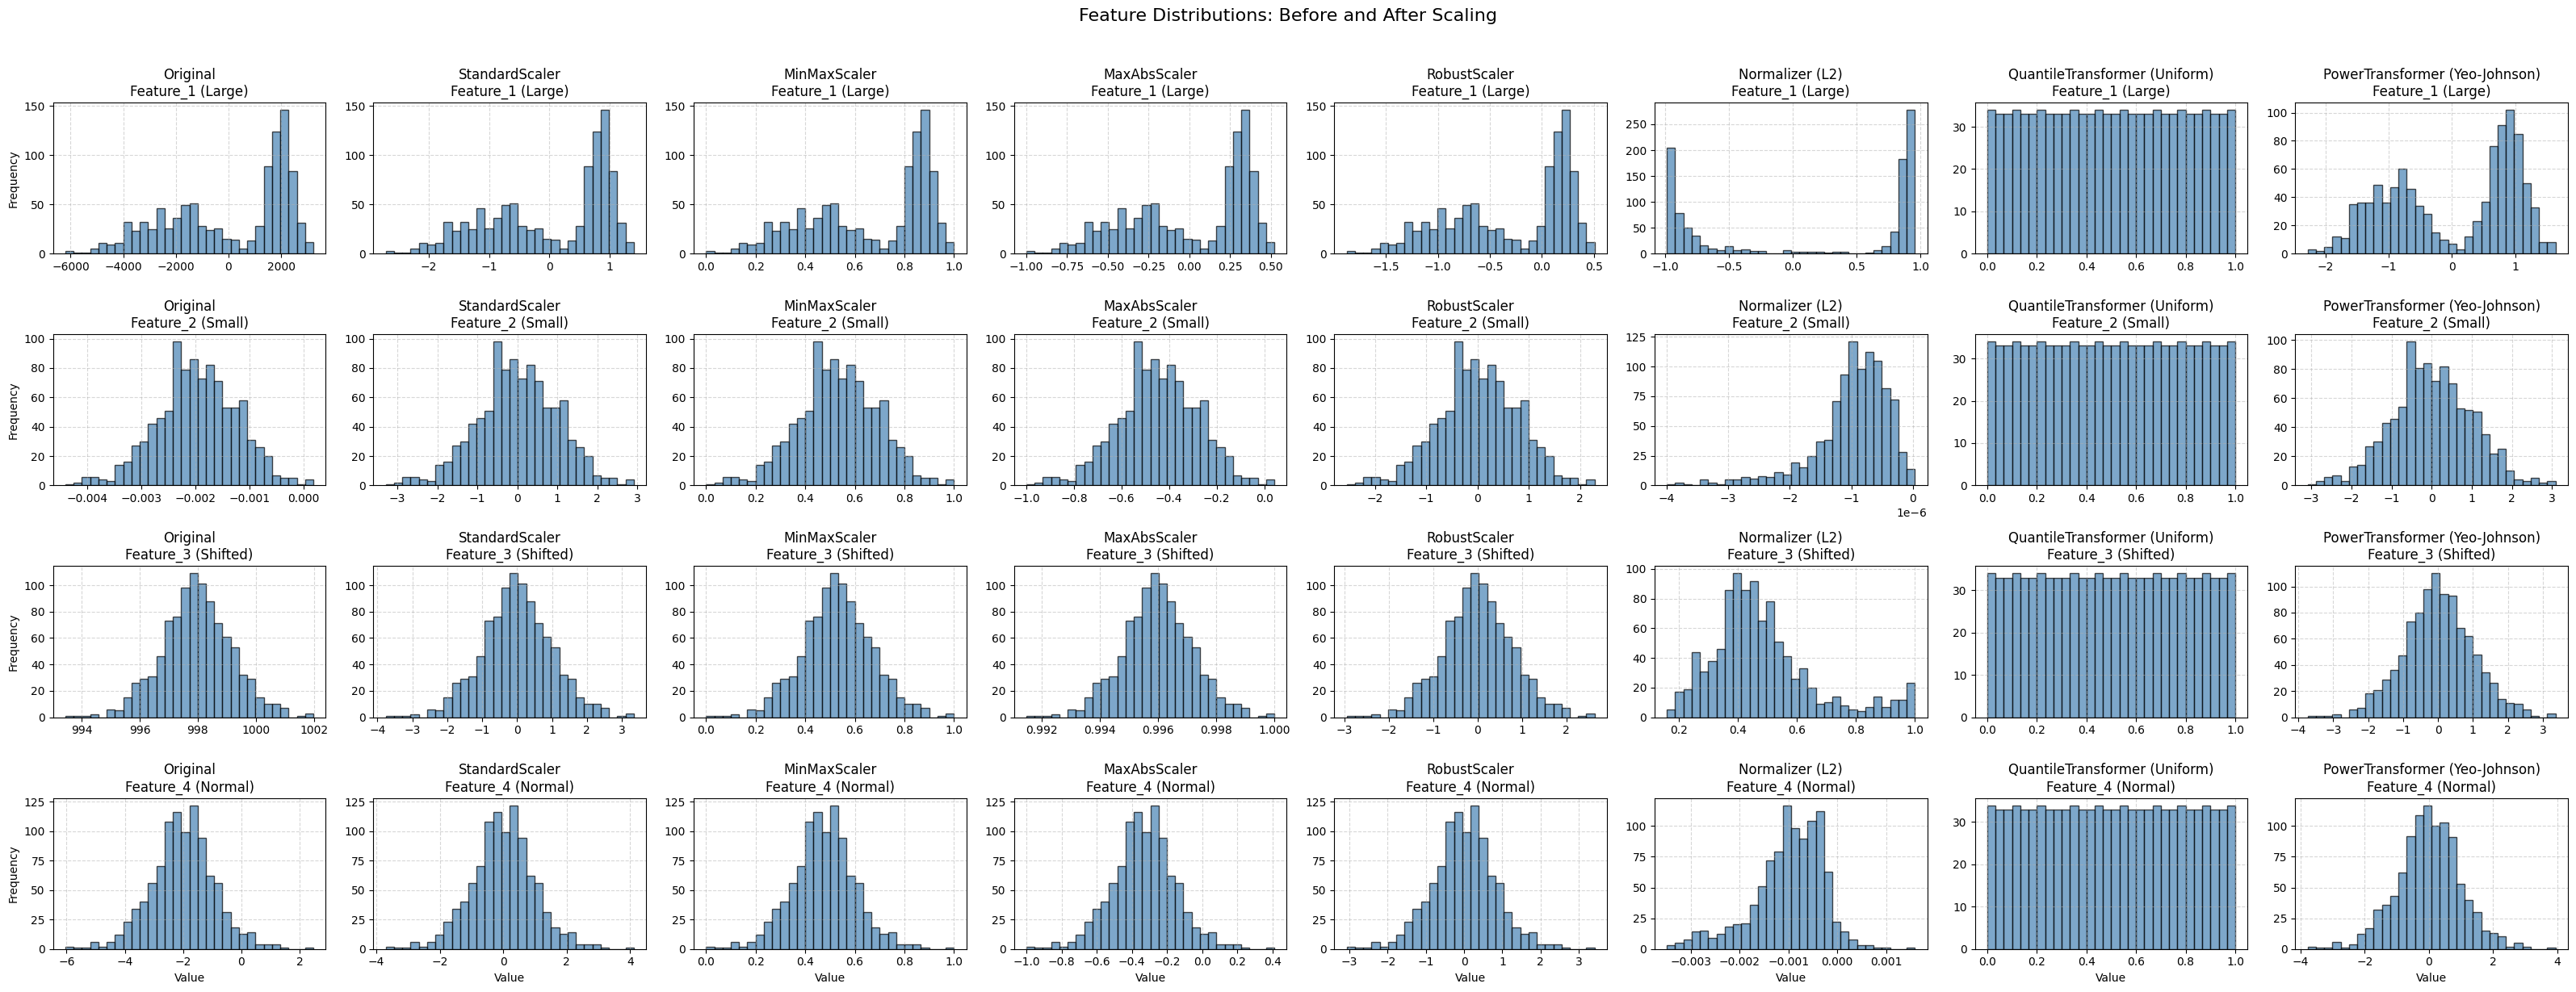


🔍 Impact of Scaling on Logistic Regression Accuracy:
Original                           : 0.9700
StandardScaler                     : 0.9867
MinMaxScaler                       : 0.9767
MaxAbsScaler                       : 0.9700
RobustScaler                       : 0.9867
Normalizer (L2)                    : 0.9667


/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_data.py:2829: UserWarning: n_quantiles (1000) is greater than the total number of samples (700). n_quantiles is set to n_samples.
  warnings.warn(


QuantileTransformer (Uniform)      : 0.9800
PowerTransformer (Yeo-Johnson)     : 0.9767


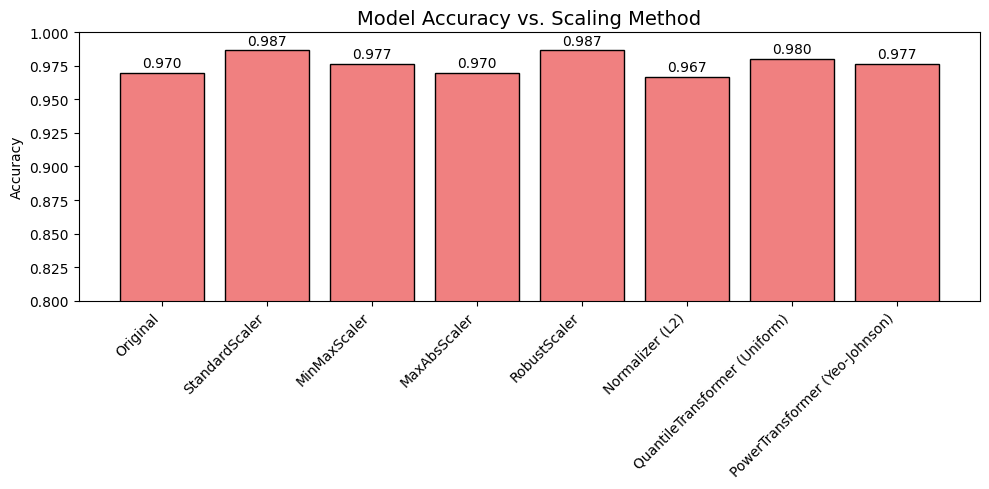

In [ ]:
# @title
# Feature Scaling Demonstration in Machine Learning
# Compatible with Google Colab

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.preprocessing import (
    StandardScaler, MinMaxScaler, MaxAbsScaler, RobustScaler,
    Normalizer, QuantileTransformer, PowerTransformer
)
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Set random seed for reproducibility
np.random.seed(42)

# ----------------------------
# 1. Create a synthetic dataset with mixed feature scales
# ----------------------------
X, y = make_classification(
    n_samples=1000,
    n_features=4,
    n_informative=4,
    n_redundant=0,
    n_clusters_per_class=1,
    class_sep=2.0,
    random_state=42
)

# Artificially distort feature scales to highlight scaling importance
X[:, 0] = X[:, 0] * 1000      # Feature 1: large magnitude (~1000s)
X[:, 1] = X[:, 1] * 0.001     # Feature 2: tiny magnitude (~0.001s)
X[:, 2] = X[:, 2] + 1000      # Feature 3: large offset
X[:, 3] = X[:, 3]             # Feature 4: baseline scale

feature_names = ['Feature_1 (Large)', 'Feature_2 (Small)', 'Feature_3 (Shifted)', 'Feature_4 (Normal)']
df_original = pd.DataFrame(X, columns=feature_names)

print("📊 Original Feature Statistics:")
print(df_original.describe().round(2))

# ----------------------------
# 2. Define all scalers
# ----------------------------
scalers = {
    'Original': None,
    'StandardScaler': StandardScaler(),
    'MinMaxScaler': MinMaxScaler(),
    'MaxAbsScaler': MaxAbsScaler(),
    'RobustScaler': RobustScaler(),
    'Normalizer (L2)': Normalizer(norm='l2'),
    'QuantileTransformer (Uniform)': QuantileTransformer(output_distribution='uniform', random_state=42),
    'PowerTransformer (Yeo-Johnson)': PowerTransformer(method='yeo-johnson')
}

# ----------------------------
# 3. Visualize distributions before and after scaling
# ----------------------------
n_scalers = len(scalers)
n_features = X.shape[1]

fig, axes = plt.subplots(n_features, n_scalers, figsize=(4 * n_scalers, 3 * n_features))
fig.suptitle('Feature Distributions: Before and After Scaling', fontsize=16, y=1.02)

for j, (name, scaler) in enumerate(scalers.items()):
    if scaler is None:
        X_scaled = X
    else:
        # Note: Normalizer works on samples (rows), not features → reshape carefully
        if name == 'Normalizer (L2)':
            X_scaled = scaler.fit_transform(X)
        else:
            X_scaled = scaler.fit_transform(X)

    for i in range(n_features):
        ax = axes[i, j] if n_scalers > 1 else axes[i]
        ax.hist(X_scaled[:, i], bins=30, alpha=0.7, color='steelblue', edgecolor='black')
        ax.set_title(f'{name}\n{feature_names[i]}')
        ax.grid(True, linestyle='--', alpha=0.5)
        if i == n_features - 1:
            ax.set_xlabel('Value')
        if j == 0:
            ax.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

# ----------------------------
# 4. Compare impact on ML model accuracy
# ----------------------------
print("\n🔍 Impact of Scaling on Logistic Regression Accuracy:")

results = {}
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

for name, scaler in scalers.items():
    if scaler is None:
        X_train_scaled = X_train
        X_test_scaled = X_test
    else:
        if name == 'Normalizer (L2)':
            # Normalizer is applied per sample → fit on train, transform both
            X_train_scaled = scaler.fit_transform(X_train)
            X_test_scaled = scaler.transform(X_test)
        else:
            X_train_scaled = scaler.fit_transform(X_train)
            X_test_scaled = scaler.transform(X_test)

    model = LogisticRegression(max_iter=1000, random_state=42)
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    results[name] = acc
    print(f"{name:35}: {acc:.4f}")

# ----------------------------
# 5. Summary plot of accuracies
# ----------------------------
plt.figure(figsize=(10, 5))
names = list(results.keys())
accuracies = list(results.values())

bars = plt.bar(names, accuracies, color='lightcoral', edgecolor='black')
plt.title('Model Accuracy vs. Scaling Method', fontsize=14)
plt.ylabel('Accuracy')
plt.ylim(0.8, 1.0)
plt.xticks(rotation=45, ha='right')
for bar, acc in zip(bars, accuracies):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002, f'{acc:.3f}',
             ha='center', va='bottom')
plt.tight_layout()
plt.show()

### 🧪 How to Use This Feature Scaling Demo

This notebook demonstrates **why feature scaling matters** and **how different scalers transform your data**. Follow these steps to get the most out of the demo:

---

#### 🔹 Step 1: Understand the Dataset
- The demo uses a **synthetic dataset** with **two features**:
  - **Feature A**: Large scale (e.g., values around 5,000–10,000) + **one strong outlier**
  - **Feature B**: Small scale (e.g., values around 0.01–0.1)
- This mimics real-world scenarios like:
  - Income (in dollars) vs. interest rate (as a decimal)
  - House size (in sq. ft.) vs. number of bathrooms

> 📌 **Goal**: See how each scaler handles differences in scale and outliers.

---

#### 🔹 Step 2: Run the Code Cells in Order
1. **Start from the top** of the notebook.
2. Click the **play button (▶)** on each code cell **in sequence**, or press `Ctrl + Enter`.
3. The first code cell generates the synthetic data and prints basic statistics.
4. The second code cell **applies 7 different scalers** and displays **histograms** showing how each transforms the data.

> ⚠️ **Do not skip cells** — later cells depend on variables defined earlier.

---

#### 🔹 Step 3: Interpret the Visualizations
- You’ll see a **grid of histograms** (2 rows × 8 columns):
  - **Row 1**: Distribution of **Feature A** (large scale + outlier)
  - **Row 2**: Distribution of **Feature B** (small scale)
  - **Columns**: Show the effect of each scaler (including "Original")

🔍 **What to look for**:
- Does the scaler **remove the outlier’s influence**? → Check `RobustScaler`
- Are values now in **[0, 1]**? → Check `MinMaxScaler`
- Is the data centered at **0 with unit variance**? → Check `StandardScaler`
- Did the **shape of the distribution change dramatically**? → Check `QuantileTransformer` or `PowerTransformer`
- For `Normalizer`: Both features per **sample** are scaled together — notice how the relationship changes!

---

#### 🔹 Step 4: Compare Scalers Using the Guidance Table
Refer to the **"Common Feature Scalers" table** in the notebook to answer:
- ❓ *"Which scaler should I use for my data?"*
- ❓ *"Why did my model perform poorly before scaling?"*

Use the table to match your **data characteristics** (e.g., outliers, sparsity, distribution) to the **right scaler**.

---

#### 🔹 Step 5: Apply to Your Own Data (Optional)
To try this with **your dataset**:
1. Replace the synthetic data generation code with your data loading (e.g., `pd.read_csv()`).
2. Select **only numerical features** (scalers don’t work on categorical data).
3. Re-run the scaling and visualization cells.

> 💡 **Tip**: Always split your data first (`train_test_split`), then **fit the scaler only on the training set** to avoid data leakage.

---

#### 🔹 Step 6: Use in Real ML Pipelines
Once you’ve chosen a scaler:
```python
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

# Scale correctly
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # ✅ Fit on TRAIN only
X_test_scaled = scaler.transform(X_test)         # ✅ Transform TEST

# Train model
model = LogisticRegression()
model.fit(X_train_scaled, y_train)

### 🚀 Final Thought

> **"Scaling doesn’t change what your data means — it changes how your model sees it."**

Proper feature scaling leads to:
- Faster training
- Better convergence
- Fairer feature contribution
- Higher model accuracy

Use it wisely! 🧠✨